In [9]:
from binance.client import Client as bnb_client
from datetime import datetime
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path

In [3]:

ticker_data = requests.get("https://api.binance.com/api/v3/ticker/24hr").json()
# Convert the API response to a DataFrame
ticker_data = pd.DataFrame(ticker_data)

# Convert volume to numeric values
ticker_data["quoteVolume"] = pd.to_numeric(
    ticker_data["quoteVolume"],
    errors="coerce"
)

top_symbols = (
    ticker_data[ticker_data["symbol"].str.endswith("USDT")]
    .sort_values("quoteVolume", ascending=False)
    .head(1000)["symbol"]
    .tolist()
)
oldest_symbols=top_symbols


In [100]:
import pandas as pd
import requests
import time


def get_all_klines(symbol, interval, start_date, end_date):
    
    url = "https://api.binance.com/api/v3/klines"

    columns = [
        'open_time',
        'open',
        'high',
        'low',
        'close',
        'volume',
        'close_time',
        'quote_volume',
        'trades',
        'taker_buy_base',
        'taker_buy_quote',
        'ignore'
    ]

    start_time = int(pd.Timestamp(start_date, tz='UTC').timestamp() * 1000)
    end_time = int(pd.Timestamp(end_date, tz='UTC').timestamp() * 1000)

    if interval.endswith("M")==False:
        interval_time = int(pd.Timedelta(interval).total_seconds() * 1000)

    all_data = []

    while start_time < end_time:
            # Convert dates to milliseconds
        if interval.endswith("M"):
            start_time = int(pd.Timestamp(start_date, tz='UTC').timestamp() * 1000)
        params = {
            'symbol': symbol,
            'interval': interval,
            'startTime': start_time,
            'endTime': end_time,
            'limit': 1000
        }

        response = requests.get(url, params=params)
        response.raise_for_status()

        batch = response.json()

        # Stop when there is no more data
        if not batch:
            break

        # Add this batch to our collection
        all_data.extend(batch)

        # Last candle's opening timestamp
        last_open_time = batch[-1][0]
        if interval.endswith("M"):
            start_date = pd.Timestamp(start_date)
            months = int(interval[:-1]) 
            start_date += pd.DateOffset(months=months)
        # Move to the next millisecond to avoid duplicates
        else:
            start_time = last_open_time + interval_time

        print(f"{symbol}: downloaded {len(all_data)} candles")

        # If fewer than 1000 were returned, we reached the end
        if len(batch) < 1000:
            break

        # Optional: be polite to the API
        time.sleep(0.1)

    # Combine everything into ONE DataFrame
    df = pd.DataFrame(all_data, columns=columns)

    # Remove any possible duplicate timestamps
    df = df.drop_duplicates(subset='open_time')

    # Convert timestamps
    df['open_time'] = pd.to_datetime(
        df['open_time'],
        unit='ms',
        utc=True
    )

    df['close_time'] = pd.to_datetime(
        df['close_time'],
        unit='ms',
        utc=True
    )

    # Convert numeric columns
    for col in ['open', 'high', 'low', 'close', 'volume']:
        df[col] = pd.to_numeric(df[col])

    return df
def get_prices(t_interval, start_date, end_date, until):
    
    symbols = oldest_symbols[:until]

    url = "https://api.binance.com/api/v3/klines"

    columns = [
        'open_time', 'open', 'high', 'low', 'close',
        'volume', 'close_time', 'quote_volume',
        'trades', 'taker_buy_base', 'taker_buy_quote',
        'ignore'
    ]

    # -------------------------------------------------
    # 1. Download prices
    # -------------------------------------------------

    data = {}

    for symbol in symbols:
        df = get_all_klines(symbol, t_interval, start_date, end_date)
        data[symbol] = df
        

    # -------------------------------------------------
    # 2. Construct price and return matrices
    # -------------------------------------------------

    # Use open_time as index so all assets align by time
    px = pd.concat(
        {
            symbol: data[symbol].set_index('open_time')['close']
            for symbol in symbols
        },
        axis=1
    )
    px.to_pickle(f'crypto_{until}_{t_interval}_{start_date}_{end_date}_px.pk')
    return px
    
def find_existing_file(t_interval, start_date, end_date,until):
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    pattern = f"crypto_{until}_{t_interval}_*_px.pk"

    for path in Path("./datasets").glob(pattern):
        try:
            # crypto_{interval}_{start}_{end}_{until}_px.pk
            parts = path.stem.split("_")

            file_start = pd.Timestamp(parts[3])
            file_end = pd.Timestamp(parts[4])

            # Does this file completely cover the requested period?
            if file_start <= start_date and file_end >= end_date:
                print(f"Using existing data: {path}")
                px = pd.read_pickle(path)
                return px

        except (ValueError, IndexError):
            continue

    
    print("Downloading data...")
    px = get_prices(t_interval, start_date, end_date,until)
    
    return px

In [89]:
def largest_complete_rectangle(df):
    available = df.notna().to_numpy()

    n_dates, n_stocks = available.shape

    best_area = 0
    best_start = None
    best_end = None
    best_stocks = None
    for start in range(n_dates):
        complete = np.ones(n_stocks, dtype=bool)
        for end in range(start, n_dates):
            complete &= available[end]
            stocks = np.flatnonzero(complete)
            area = (end - start + 1) * len(stocks)
            if area > best_area:
                best_area = area
                best_start = start
                best_end = end
                best_stocks = stocks.copy()
    selected_stocks = df.columns[best_stocks]
    return {
        "start_date": df.index[best_start],
        "end_date": df.index[best_end],
        "dates": df.index[best_start:best_end + 1],
        "stocks": selected_stocks,
        "n_dates": best_end - best_start + 1,
        "n_stocks": len(selected_stocks),
        "area": best_area,
    }

In [98]:
def ret_treatment(ret):
    ret = ret.dropna(axis=0, how="all") 
    ret = ret.dropna(axis=1, how="all") 
    rect=largest_complete_rectangle(ret)
    ret = ret[rect["stocks"]].loc[rect["dates"]]

In [99]:
def alpha_beta(t_interval, start_date, end_date,until):
    
    px = find_existing_file(t_interval, start_date, end_date,until).loc[start_date:end_date]
    
    ret = ret_treatment(px.pct_change())

    ret_mean = ret.mean(axis=1).rename("mkt") 
    X = sm.add_constant(ret_mean)
    Y = ret
    results = {i:sm.OLS(Y[i], X).fit() for i in ret.columns}
    beta_contr = {i:results[i].params["mkt"]*X["mkt"]  for i in ret.columns}
    prediction = {i:results[i].params["mkt"]*X["mkt"] + results[i].params['const'] for i in ret.columns}
    alpha_contr = {i:results[i].params['const'] + results[i].resid for i in ret.columns}
    
    return ret, beta_contr, alpha_contr

def plot_beta(ret,beta_contr):
    for i in ret.columns:
        beta_contr[i].cumsum().plot() 

def plot_alpha(ret,alpha_contr):
    for i in ret.columns:
        alpha_contr[i].cumsum().plot()

In [86]:
ret,beta,alpha=alpha_beta('1d', '2017-01-01', '2026-09-14', 1000)

Using existing data: crypto_1000_1d_2017-01-01_2026-09-14_px.pk


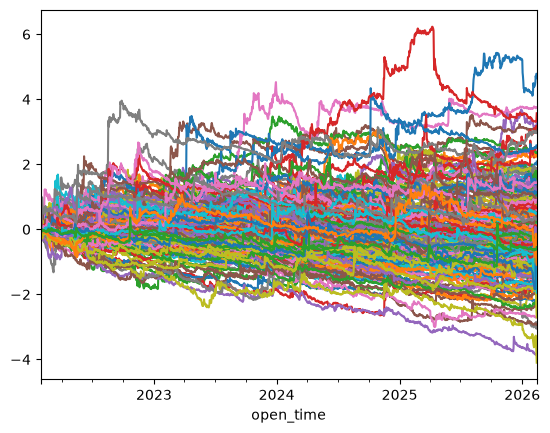

In [87]:
plot_alpha(ret,alpha)

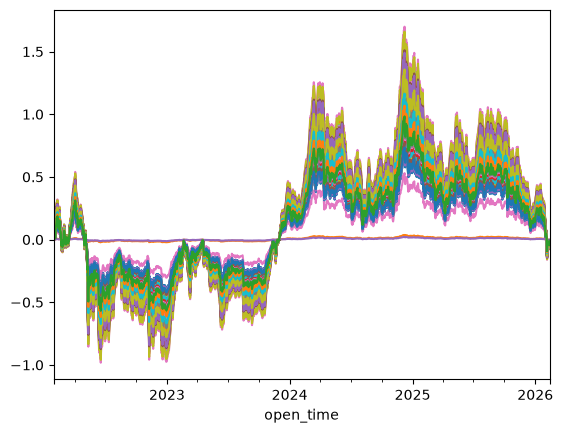

In [88]:
plot_beta(ret,beta)

# RISK FACTORS

In [102]:
px = pd.read_pickle("datasets/crypto_100_1d_2017-01-01_2026-09-09_px.pk")
vol = pd.read_pickle("datasets/crypto_100_1d_2017-01-01_2026-09-09_vol.pk")